IMPORT LIBRARY

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.fft import fft, fftfreq



LOAD DATASET

In [7]:
df = pd.read_csv("waves_data.csv")
df

,Date/Time,Hs,Hmax,Tz,Tp,Peak Direction,SST
0,01/01/2017 00:00,-99.900,-99.90,-99.900,-99.900,-99.9,-99.90
1,01/01/2017 00:30,0.875,1.39,4.421,4.506,-99.9,-99.90
2,01/01/2017 01:00,0.763,1.15,4.520,5.513,49.0,25.65
3,01/01/2017 01:30,0.770,1.41,4.582,5.647,75.0,25.50
4,01/01/2017 02:00,0.747,1.16,4.515,5.083,91.0,25.45
...,...,...,...,...,...,...,...
43723,30/06/2019 21:30,2.299,3.60,9.281,12.765,94.0,21.95
43724,30/06/2019 22:00,2.075,3.04,9.303,12.722,95.0,21.95
43725,30/06/2019 22:30,2.157,3.43,9.168,12.890,97.0,21.95
43726,30/06/2019 23:00,2.087,2.84,8.706,10.963,92.0,21.95


In [8]:
print(df.columns)


Index(['Date/Time', 'Hs', 'Hmax', 'Tz', 'Tp', 'Peak Direction', 'SST'], dtype='object')


In [9]:
print(df['Date/Time'].head(10))

0    01/01/2017 00:00
1    01/01/2017 00:30
2    01/01/2017 01:00
3    01/01/2017 01:30
4    01/01/2017 02:00
5    01/01/2017 02:30
6    01/01/2017 03:00
7    01/01/2017 03:30
8    01/01/2017 04:00
9    01/01/2017 04:30
Name: Date/Time, dtype: object


In [15]:
data = pd.read_csv("waves_data.csv")

In [18]:
print("Jumlah data :", len(hs))
print("Rata-rata Hs :", np.mean(hs))
print("Std Dev Hs   :", np.std(hs))
print("Nilai max/min:", np.max(hs), "/", np.min(hs))
ax/min:", np.max(Hs), "/", np.min(Hs))

SyntaxError: unterminated string literal (detected at line 5) (1325926989.py, line 5)

PRE-PROCESSING DATA

In [ ]:
# Convert waktu (format DD/MM/YYYY)
df['Date/Time'] = pd.to_datetime(
    df['Date/Time'], 
    dayfirst=True,
    format='mixed'
)

NameError: name 'pd' is not defined

In [ ]:
df = df.sort_values('Date/Time')

In [ ]:
df = df.dropna(subset=['Hs'])

In [ ]:
dt = (df['Date/Time'].iloc[1] - df['Date/Time'].iloc[0]).total_seconds()
print("Sampling interval (dt):", dt, "detik")

Sampling interval (dt): 1800.0 detik


Smoothing Sinyal

In [ ]:
time = df['Date/Time']
hs = df['Hs']   # tinggi gelombang


In [ ]:
subset = df.iloc[:7200]

subset_time = subset['Date/Time']
subset_hs = subset['Hs']

# smoothing subset (karena digunakan untuk plot)
subset_hs_smooth = savgol_filter(subset_hs, window_length=21, polyorder=2)


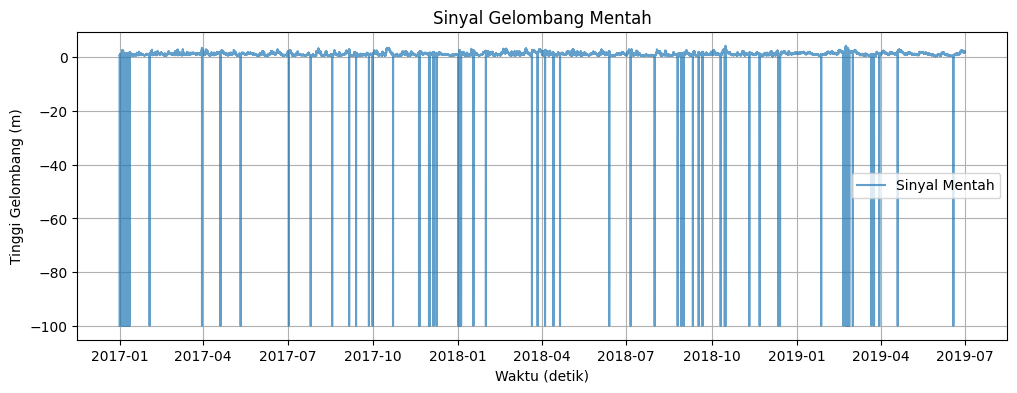

In [ ]:
plt.figure(figsize=(12,4))
plt.plot(time, hs, label='Sinyal Mentah', alpha=0.7)
plt.xlabel("Waktu (detik)")
plt.ylabel("Tinggi Gelombang (m)")
plt.title("Sinyal Gelombang Mentah")
plt.legend()
plt.grid(True)
plt.show()


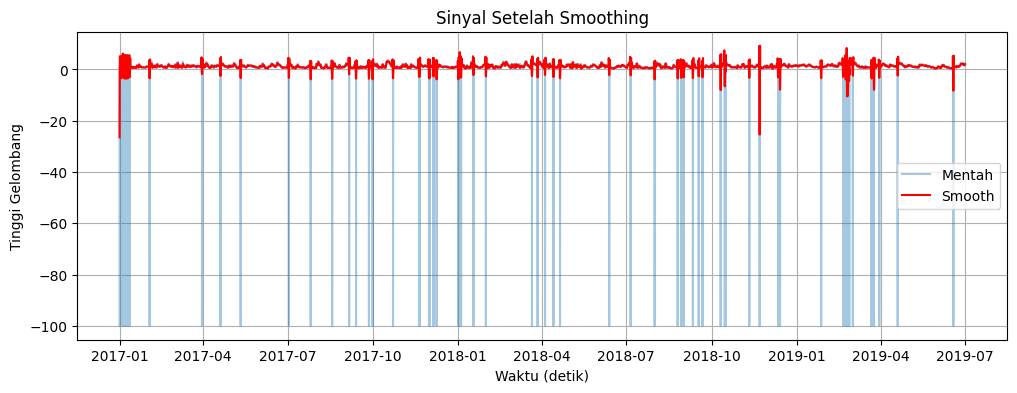

In [ ]:
hs_smooth = savgol_filter(hs, window_length=51, polyorder=3)

plt.figure(figsize=(12,4))
plt.plot(time, hs, alpha=0.4, label='Mentah')
plt.plot(time, hs_smooth, color='red', label='Smooth')
plt.title("Sinyal Setelah Smoothing")
plt.xlabel("Waktu (detik)")
plt.ylabel("Tinggi Gelombang")
plt.legend()
plt.grid(True)
plt.show()


FFT 

In [ ]:
hs_full_smooth = savgol_filter(hs, 51, 3)

dt = (time.iloc[1] - time.iloc[0]).total_seconds()
N = len(hs_full_smooth)

Y = fft(hs_full_smooth)
freq = fftfreq(N, d=dt)

mask = freq > 0
freq_pos = freq[mask]
amp = np.abs(Y[mask])



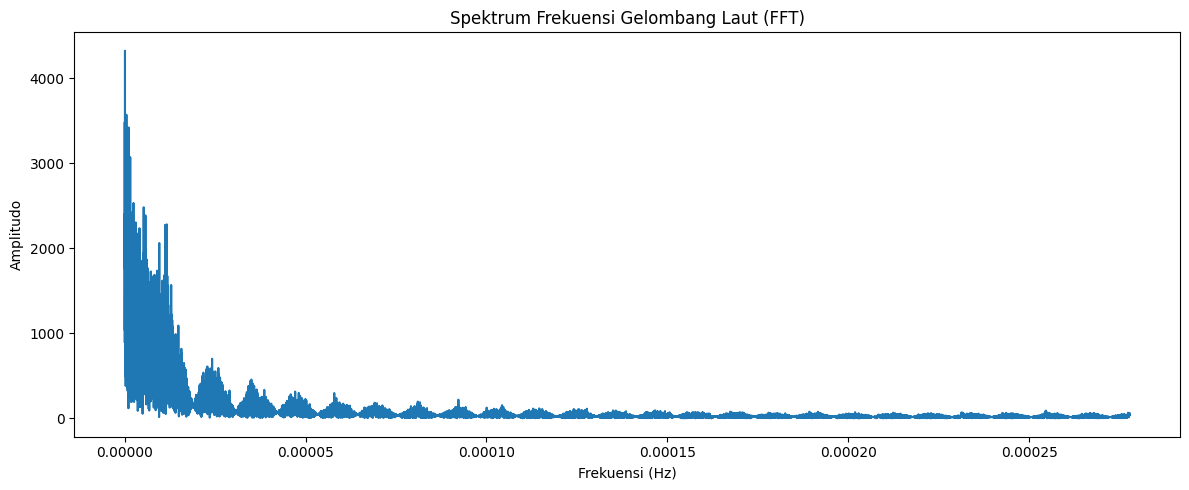

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(freq_pos, amp)
plt.xlabel('Frekuensi (Hz)')
plt.ylabel('Amplitudo')
plt.title('Spektrum Frekuensi Gelombang Laut (FFT)')
plt.tight_layout()
plt.show()



In [ ]:
idx = np.argmax(amp)
dominant_freq = freq_pos[idx]
dominant_period = 1 / dominant_freq

print("Frekuensi Dominan:", round(dominant_freq, 5), "Hz")
print("Periode Dominan:", round(dominant_period, 2), "detik")



Frekuensi Dominan: 0.0 Hz
Periode Dominan: 9838800.0 detik


Validasi FFT Menggunaan TP & TZ

In [ ]:
tp = df['Tp'] if 'Tp' in df.columns else None
tz = df['Tz'] if 'Tz' in df.columns else None


In [ ]:
TP_index = np.argmax(Y_pos)
TP_value = freq_pos[TP_index]

print("Frekuensi Dominan (TP):", TP_value, "Hz")




Frekuensi Dominan (TP): 1.016384111883563e-07 Hz


In [ ]:
TZ = time[0]
print("Validasi TZ (waktu awal sinyal):", TZ)


Validasi TZ (waktu awal sinyal): 2017-01-01 00:00:00


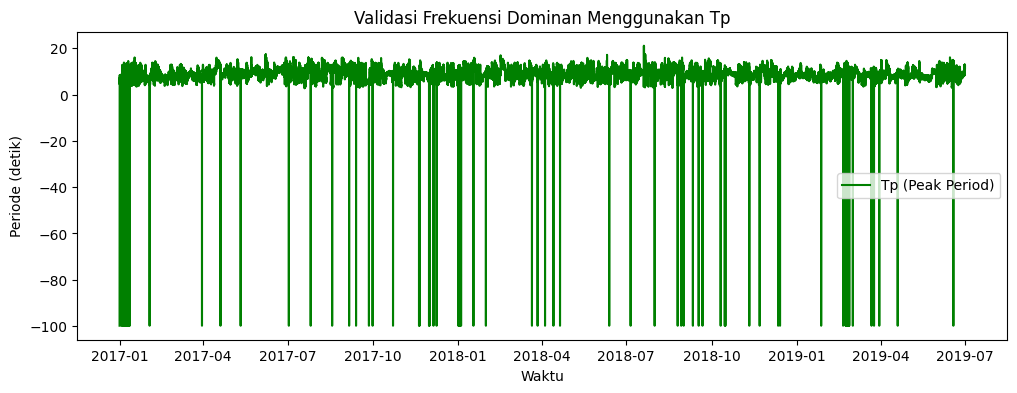

In [ ]:
if tp is not None:
    plt.figure(figsize=(12,4))
    plt.plot(time, tp, label='Tp (Peak Period)', color='green')
    plt.xlabel('Waktu')
    plt.ylabel('Periode (detik)')
    plt.title('Validasi Frekuensi Dominan Menggunakan Tp')
    plt.legend()
    plt.show()


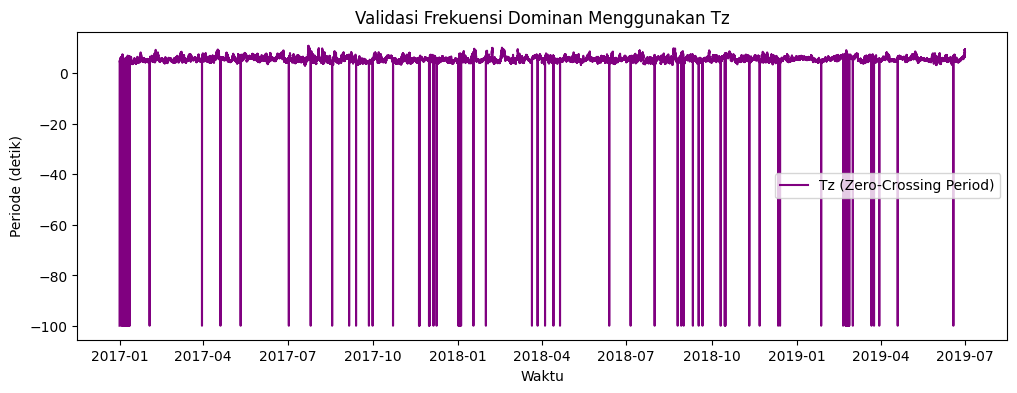

In [ ]:
if tz is not None:
    plt.figure(figsize=(12,4))
    plt.plot(time, tz, label='Tz (Zero-Crossing Period)', color='purple')
    plt.xlabel('Waktu')
    plt.ylabel('Periode (detik)')
    plt.title('Validasi Frekuensi Dominan Menggunakan Tz')
    plt.legend()
    plt.show()
